# Monte Carlo Policy Gradient (REINFORCE) on CartPole

## What I'm doing
I'll teach an agent to balance a pole on a cart by learning a **policy** π(a|s)
directly — no value function, no Q-learning, no target network.

## The core idea
- Run a full episode with the current policy.
- Look at the **return** G_t = r_t + γ·r_{t+1} + γ²·r_{t+2} + ... from each step.
- If an action led to a high return → I make it *more likely* next time.
- If it led to a low return → I make it *less likely*.

## The gradient I use
$$
\nabla_\theta J(\theta) \;=\; \mathbb{E}\left[ \sum_t \nabla_\theta \log \pi_\theta(a_t \mid s_t) \cdot G_t \right]
$$

That's the whole algorithm. Everything below is just plumbing.

## Step 1 — Imports

- `gymnasium` — the environment (CartPole).
- `torch` — for the neural network and automatic differentiation.
- `numpy` — small helpers (not strictly required).

> If anything fails to import: `!pip install gymnasium torch` in a code cell.

In [2]:
import numpy as np
import gymnasium as gym
import torch
import torch.nn as nn
import torch.optim as optim

# Reproducibility (optional)
torch.manual_seed(0)
np.random.seed(0)

## Step 2 — The policy network

A policy for discrete actions is just a classifier: **state → probability over actions**.

- Input:  state vector (4 numbers for CartPole)
- Hidden: small MLP
- Output: softmax → a probability for each action (2 for CartPole: left, right)

Why softmax? Because the actions are categorical, and softmax gives me
a valid probability distribution I can sample from and take `log` of.

In [3]:
class PolicyNet(nn.Module):
    def __init__(self, state_dim: int, action_dim: int, hidden: int = 64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, action_dim),
        )

    def forward(self, state):
        logits = self.net(state)             # raw scores
        return torch.softmax(logits, dim=-1) # probabilities π(·|s)

## Step 3 — Sanity check

Before training, I confirm the network returns a valid probability distribution
for a random state.

In [4]:
policy = PolicyNet(state_dim=4, action_dim=2)

s = torch.tensor([0.1, -0.2, 0.05, 0.3], dtype=torch.float32)
probs = policy(s)
print("probs:", probs)
print("sum:  ", probs.sum().item())   # should be ~1.0

probs: tensor([0.5353, 0.4647], grad_fn=<SoftmaxBackward0>)
sum:   1.0


## Step 4 — Collect one episode

I roll out the policy until the environment says "done".
For each step I record:
- `log_prob` — $\log \pi_\theta(a_t \mid s_t)$ (needed for the gradient)
- `reward` — the immediate reward $r_t$ (needed for the return)

**Why `torch.distributions.Categorical`?**
It gives me `.sample()` (to pick an action) and `.log_prob()` (the gradient term)
in one clean object — no manual `log(softmax(...))` and no `multinomial` calls.

In [11]:
def collect_episode(env, policy):
    state, _ = env.reset()
    log_probs, rewards = [], []
    done = False

    while not done:
        state_t = torch.tensor(state, dtype=torch.float32)
        probs   = policy(state_t)
        dist    = torch.distributions.Categorical(probs)

        action   = dist.sample()
        log_prob = dist.log_prob(action)

        state, reward, terminated, truncated, _ = env.step(action.item())
        done = terminated or truncated

        log_probs.append(log_prob)
        rewards.append(reward)

    return log_probs, rewards

In [6]:
policy = PolicyNet(state_dim=4, action_dim=2)

s = torch.tensor([0.1, -0.2, 0.05, 0.3], dtype=torch.float32)
probs = policy(s)
print("probs:", probs)
print("sum:  ", probs.sum().item())   # should be ~1.0

probs: tensor([0.5048, 0.4952], grad_fn=<SoftmaxBackward0>)
sum:   1.0


## Step 4 — Collect one episode

I roll out the policy until the environment says "done".
For each step I record:
- `log_prob` — $\log \pi_\theta(a_t \mid s_t)$ (needed for the gradient)
- `reward` — the immediate reward $r_t$ (needed for the return)

**Why `torch.distributions.Categorical`?**
It gives me `.sample()` (to pick an action) and `.log_prob()` (the gradient term)
in one clean object — no manual `log(softmax(...))` and no `multinomial` calls.

In [12]:
def collect_episode(env, policy):
    state, _ = env.reset()
    log_probs, rewards = [], []
    done = False

    while not done:
        state_t = torch.tensor(state, dtype=torch.float32)
        probs   = policy(state_t)
        dist    = torch.distributions.Categorical(probs)

        action   = dist.sample()
        log_prob = dist.log_prob(action)

        state, reward, terminated, truncated, _ = env.step(action.item())
        done = terminated or truncated

        log_probs.append(log_prob)
        rewards.append(reward)

    return log_probs, rewards

## Step 5 — Compute returns $G_t$

The return from step $t$ is:

$$
G_t = r_t + \gamma r_{t+1} + \gamma^2 r_{t+2} + \dots
$$

I compute it **backwards** in O(T) time:

$$
G_T = r_T, \quad G_t = r_t + \gamma \, G_{t+1}
$$

This is the "Monte Carlo" part: I use the actual outcome of the episode,
not a value-function estimate.

In [9]:
def compute_returns(rewards, gamma=0.99):
    G = 0.0
    returns = []
    for r in reversed(rewards):
        G = r + gamma * G
        returns.insert(0, G)
    return torch.tensor(returns, dtype=torch.float32)

## Step 6 — Why I normalize returns

REINFORCE's raw gradient estimate is *extremely* noisy.
A simple variance-reduction trick that is mathematically neutral (it adds a
state-independent baseline) is to standardize the returns within the episode:

$$
\hat{G}_t = \frac{G_t - \text{mean}(G)}{\text{std}(G) + \epsilon}
$$

Without this, CartPole often refuses to learn with a small learning rate.
I fold it into the loss directly below.

In [10]:
def normalize(returns):
    return (returns - returns.mean()) / (returns.std() + 1e-8)

## Step 7 — The policy-gradient loss

For one episode, the loss is:

$$
\mathcal{L}(\theta) \;=\; - \sum_t \log \pi_\theta(a_t \mid s_t) \cdot \hat{G}_t
$$

The **minus sign** is because PyTorch minimizes. Minimizing `-log π · G` = maximizing `log π · G`,
which pushes up the probability of actions that led to high returns.

I don't need to write the gradient by hand — `loss.backward()` computes it.

In [13]:
def policy_gradient_loss(log_probs, returns):
    returns = normalize(returns)
    log_probs = torch.stack(log_probs)          # shape (T,)
    return -(log_probs * returns).sum()

## Step 8 — The full training loop

One episode = one gradient step. This is the original REINFORCE algorithm:

1. Collect an episode with the current policy.
2. Compute returns $G_t$.
3. Build the loss $\mathcal{L} = -\sum \log \pi \cdot \hat{G}$.
4. `loss.backward()` → `optimizer.step()`.
5. Repeat.

Notice `optimizer.zero_grad()` — I must call it every iteration, otherwise
gradients accumulate across episodes and training diverges.

In [14]:
def train(num_episodes=500, gamma=0.99, lr=1e-2, log_every=50):
    env = gym.make("CartPole-v1")
    state_dim  = env.observation_space.shape[0]
    action_dim = env.action_space.n

    policy    = PolicyNet(state_dim, action_dim)
    optimizer = optim.Adam(policy.parameters(), lr=lr)

    episode_returns = []   # for plotting later

    for ep in range(1, num_episodes + 1):
        log_probs, rewards = collect_episode(env, policy)
        returns = compute_returns(rewards, gamma)

        loss = policy_gradient_loss(log_probs, returns)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        episode_returns.append(sum(rewards))

        if ep % log_every == 0:
            avg = np.mean(episode_returns[-log_every:])
            print(f"Episode {ep:4d} | avg return (last {log_every}): {avg:6.1f}")

    env.close()
    return policy, episode_returns

## Step 9 — Run it

CartPole-v1 gives reward **1 per step** and ends at 500 steps, so a return of 500 = perfect.
A random policy scores ~20. If my implementation is correct, this should
rapidly climb past 100 and often reach 400–500.

Typical runtime: under a minute on a laptop CPU.

In [15]:
policy, returns_hist = train(num_episodes=500, gamma=0.99, lr=1e-2, log_every=50)

Episode   50 | avg return (last 50):   83.2
Episode  100 | avg return (last 50):  303.6
Episode  150 | avg return (last 50):  415.0
Episode  200 | avg return (last 50):  479.8
Episode  250 | avg return (last 50):  491.7
Episode  300 | avg return (last 50):  471.6
Episode  350 | avg return (last 50):  472.3
Episode  400 | avg return (last 50):  483.3
Episode  450 | avg return (last 50):  384.9
Episode  500 | avg return (last 50):  458.2


## Step 10 — Visualize learning

A learning curve should show the return increasing over episodes.
The early flat/low region is the random-policy phase; the rise is where
the gradient signal starts to dominate.

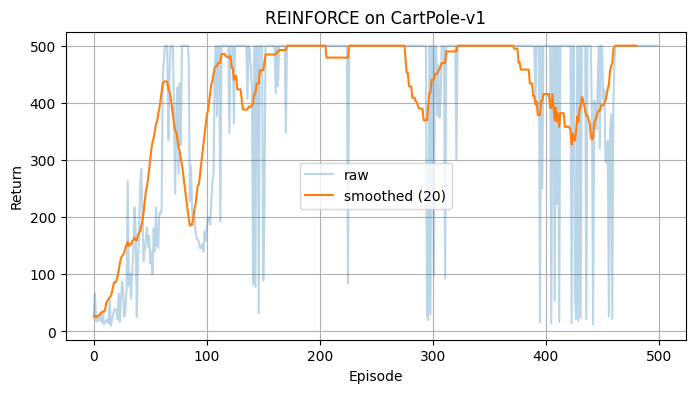

In [16]:
import matplotlib.pyplot as plt

def smooth(x, k=20):
    x = np.asarray(x, dtype=float)
    if len(x) < k:
        return x
    kernel = np.ones(k) / k
    return np.convolve(x, kernel, mode="valid")

plt.figure(figsize=(8, 4))
plt.plot(returns_hist, alpha=0.3, label="raw")
plt.plot(smooth(returns_hist, 20), label="smoothed (20)")
plt.xlabel("Episode")
plt.ylabel("Return")
plt.title("REINFORCE on CartPole-v1")
plt.legend()
plt.grid(True)
plt.show()